Florian Huber's weather prediction dataset is available on Zenodo: <https://doi.org/10.5281/zenodo.4770936>.
Our aim for this episode is to train a neural network to predict the weather for a given location.

In [1]:
import pandas as pd

In [2]:
weather_prediction_data = pd.read_csv('https://zenodo.org/records/5071376/files/weather_prediction_dataset.csv?download=1')

In [3]:
weather_prediction_data.shape

(3654, 165)

In [4]:
weather_prediction_data.head()

,DATE,MONTH,BASEL_cloud_cover,BASEL_humidity,BASEL_pressure,BASEL_global_radiation,BASEL_precipitation,BASEL_sunshine,BASEL_temp_mean,BASEL_temp_min,...,STOCKHOLM_temp_min,STOCKHOLM_temp_max,TOURS_wind_speed,TOURS_humidity,TOURS_pressure,TOURS_global_radiation,TOURS_precipitation,TOURS_temp_mean,TOURS_temp_min,TOURS_temp_max
0,20000101,1,8,0.89,1.0286,0.20,0.03,0.0,2.9,1.6,...,-9.3,0.7,1.6,0.97,1.0275,0.25,0.04,8.5,7.2,9.8
1,20000102,1,8,0.87,1.0318,0.25,0.00,0.0,3.6,2.7,...,0.5,2.0,2.0,0.99,1.0293,0.17,0.16,7.9,6.6,9.2
2,20000103,1,5,0.81,1.0314,0.50,0.00,3.7,2.2,0.1,...,-1.0,2.8,3.4,0.91,1.0267,0.27,0.00,8.1,6.6,9.6
3,20000104,1,7,0.79,1.0262,0.63,0.35,6.9,3.9,0.5,...,2.5,4.6,4.9,0.95,1.0222,0.11,0.44,8.6,6.4,10.8
4,20000105,1,5,0.90,1.0246,0.51,0.07,3.7,6.0,3.8,...,-1.8,2.9,3.6,0.95,1.0209,0.39,0.04,8.0,6.4,9.5


In [19]:
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split

In [10]:
three_years = 365 * 3

In [14]:
features = weather_prediction_data.drop(columns=["DATE", "MONTH"]).iloc[:three_years]

In [15]:
target = weather_prediction_data["BASEL_sunshine"].iloc[1:three_years+1]

In [16]:
features.shape

(1095, 163)

In [17]:
target.shape

(1095,)

In [20]:
X_train, X_holdout, y_train, y_holdout = train_test_split(features, target, test_size=0.3, random_state=0) # no shuffle, to match what is done in the deep-learning-intro lesson

In [21]:
X_val, X_test, y_val, y_test = train_test_split(X_holdout, y_holdout, test_size=0.5, random_state=0)

In [22]:
basel_sunshine_predictor = MLPRegressor()

In [23]:
basel_sunshine_predictor.fit(X=X_train, y=y_train)

/Users/hodges/miniforge3/envs/aicarpentry-dev-workshop/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",200
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


* explore the parameters of MLPRegressor, discuss whether the defaults are appropriate or not
* could play with max_iter to see if the model converges when given more "time"
* predict values and plot performance
* maybe scale the input data? look at ranges of columns, if they have vastly different ranges then the network will learn the larger ranges and ignore the smaller ones. This could make a nice before/after comparison for the end of the episode.
* check for overfitting as seen in the equivalent deep-learning-intro episode.

### 2026/11/03

* Trying to look at some results/outputs
* plotting default loss vs epochs
* plot root mean square error? (have looked at this in RF, so reinforces concept, check alignment of episodes)
* plotting correlation between predicted and true sunshine hours, for training and for test data
  - perhaps also plot sunshine hours over time, to see the time series?

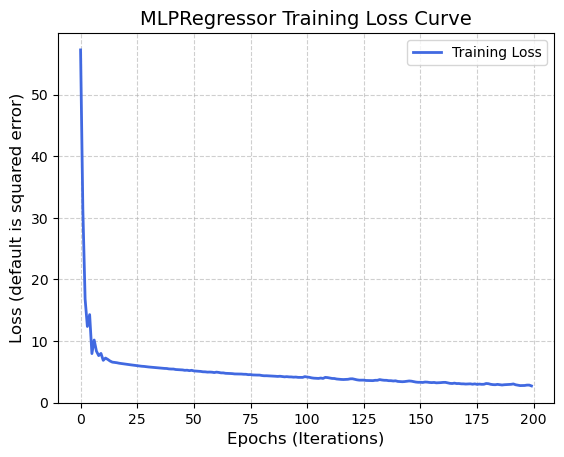

In [15]:
plt.plot(basel_sunshine_predictor.loss_curve_, label="Training Loss", color="royalblue", lw=2)
plt.xlabel("Epochs (Iterations)", fontsize=12)
plt.ylabel("Loss (default is squared error)", fontsize=12)
plt.title("MLPRegressor Training Loss Curve", fontsize=14)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()

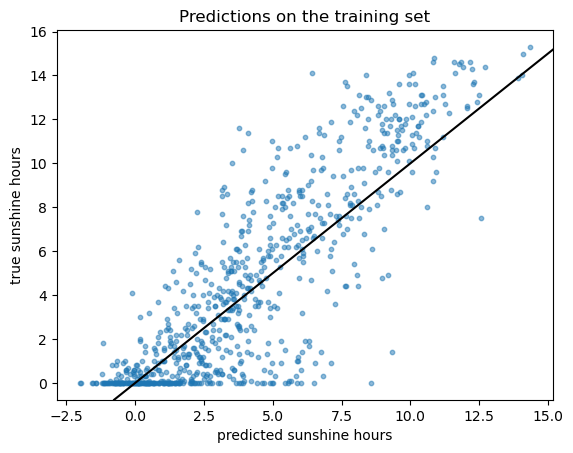

In [16]:
predicted = basel_sunshine_predictor.predict(X=X_train)

plt.scatter(predicted, y_train, s=10, alpha=0.5)
plt.axline((0,0), slope=1, color='k') # plot diagonal reference line
plt.xlabel("predicted sunshine hours")
plt.ylabel("true sunshine hours")
plt.title("Predictions on the training set")
plt.show()

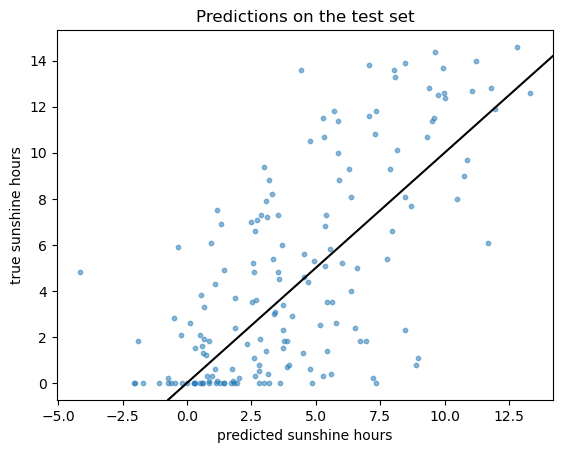

In [17]:
predicted = basel_sunshine_predictor.predict(X=X_test)

plt.scatter(predicted, y_test, s=10, alpha=0.5)
plt.axline((0,0), slope=1, color='k') # plot diagonal reference line
plt.xlabel("predicted sunshine hours")
plt.ylabel("true sunshine hours")
plt.title("Predictions on the test set")
plt.show()

* looks like this could be improved -> hyperparameter tuning?